<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 2 · Sesión 3: Verosimilitud, inferencia y lectura de resultados estadísticos</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: MLE, Fisher y Hessiano, tests de Wald/LR/score, IC perfilados, AIC/BIC y salida de statsmodels</div>
</div>

## Objetivos de la sesión (2 horas)

1. Entender la **verosimilitud** y el **estimador de máxima verosimilitud** (MLE), la base de la regresión logística.
2. Derivar el **error estándar** desde la información de Fisher y el Hessiano.
3. Usar la **trinidad de tests**: Wald, razón de verosimilitud (LR) y score; comparar modelos anidados.
4. Construir intervalos de **verosimilitud perfilada** y compararlos con los de Wald.
5. Comparar modelos no anidados con **AIC y BIC**, y leer la **salida estadística** completa de un modelo.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 35 min | Verosimilitud, MLE, Fisher y MLE numérico de una logística |
| 2 | 25 min | Lectura de resultados estadísticos |
| 3 | 30 min | Wald, LR y score; modelos anidados; IC perfilados |
| 4 | 20 min | AIC, BIC y deviance |
| 5 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

from scipy import stats, optimize
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint
app = pd.read_csv(DATA / "hc_application_sintetico.csv")
german = pd.read_csv(DATA / "german_credit.csv")
rng = np.random.default_rng(2027)

## 1. Verosimilitud y máxima verosimilitud
Dados datos $d_1, \dots, d_n$ con $D_i \sim \text{Bernoulli}(p)$:
$$\mathcal{L}(p) = \prod_{i=1}^n p^{d_i}(1-p)^{1-d_i}, \qquad \ell(p) = \log \mathcal{L}(p) = k \log p + (n-k)\log(1-p)$$
Derivando e igualando a cero: $\hat p_{MLE} = k/n$. La **curvatura** de $\ell$ en el máximo (información de Fisher) da el error estándar:
$$I(p) = \frac{n}{p(1-p)} \quad\Rightarrow\quad SE(\hat p) = \sqrt{\hat p(1-\hat p)/n}$$

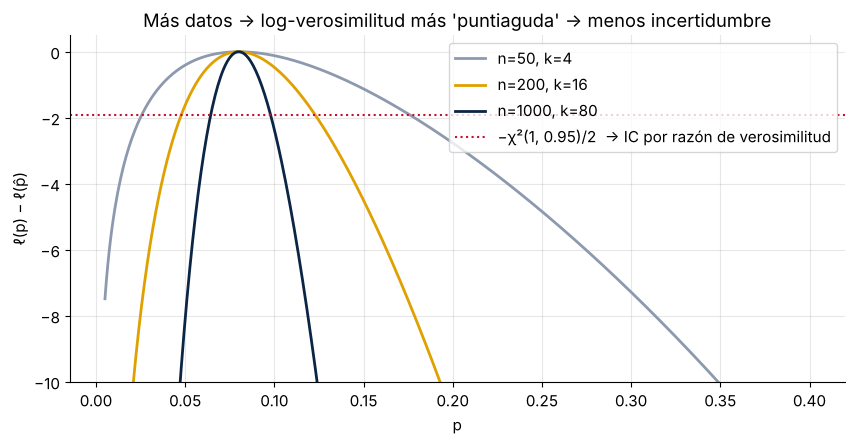

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.5))
grid = np.linspace(0.005, 0.4, 500)
for n, c in [(50, GRIS), (200, ORO), (1000, AZUL)]:
    k = round(0.08 * n)
    ll = k * np.log(grid) + (n - k) * np.log(1 - grid)
    ax.plot(grid, ll - ll.max(), color=c, lw=2, label=f"n={n}, k={k}")
ax.axhline(-1.92, color=ROJO, ls=":", label="−χ²(1, 0.95)/2  → IC por razón de verosimilitud")
ax.set_ylim(-10, 0.5); ax.set_xlabel("p"); ax.set_ylabel("ℓ(p) − ℓ(p̂)"); ax.legend(); ax.set_title("Más datos → log-verosimilitud más 'puntiaguda' → menos incertidumbre")
plt.show()

### MLE numérico: de una PD constante a una PD que depende de $x$
Si dejamos que $p_i$ dependa de las características del cliente mediante $p_i = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_i)}}$, maximizar $\ell(\beta)$ es exactamente **estimar una regresión logística**. Hagámoslo "a mano" con un optimizador y comparemos con `statsmodels`.

In [3]:
x = german["duration_in_month"].values
yv = german["default"].values
def neg_loglik(beta):
    eta = beta[0] + beta[1] * x
    return -np.sum(yv * eta - np.log1p(np.exp(eta)))
opt = optimize.minimize(neg_loglik, x0=[0, 0], method="BFGS")
# Error estándar desde el Hessiano analítico de la log-verosimilitud: H = X' W X, con W = diag(p(1-p))
Xd = np.column_stack([np.ones_like(x), x]).astype(float)
p_fit = 1 / (1 + np.exp(-Xd @ opt.x))
H = Xd.T @ (Xd * (p_fit * (1 - p_fit))[:, None])
se_manual = np.sqrt(np.diag(np.linalg.inv(H)))       # (la aproximación hess_inv de BFGS NO es confiable para esto)
print("MLE manual:   beta =", opt.x.round(4), " SE aprox =", se_manual.round(4), " logLik =", round(-opt.fun, 2))
m = sm.Logit(yv, sm.add_constant(x)).fit(disp=0)
print("statsmodels:  beta =", m.params.round(4), " SE =", m.bse.round(4), " logLik =", round(m.llf, 2))

MLE manual:   beta = [-1.6664  0.0375]  SE aprox = [0.1466 0.0057]  logLik = -588.56
statsmodels:  beta = [-1.6664  0.0375]  SE = [0.1466 0.0057]  logLik = -588.56


## 2. Lectura de resultados estadísticos
Estimemos un modelo con varias variables del *German Credit* (datos reales, 1 000 créditos, 30 % malos) y leamos la salida **como lo haría un comité de validación**.

In [4]:
g = german.copy()
g["sin_cuenta_corriente"] = (g["status_of_existing_checking_account"] == "no checking account").astype(int)
g["historia_critica"] = (g["credit_history"].str.contains("critical")).astype(int)
g["ahorro_bajo"] = (g["savings_account_and_bonds"] == "... < 100 DM").astype(int)
g["log_monto"] = np.log(g["credit_amount"])
X = sm.add_constant(g[["duration_in_month", "log_monto", "age_in_years", "sin_cuenta_corriente", "historia_critica", "ahorro_bajo",
                       "installment_rate_in_percentage_of_disposable_income"]])
modelo = sm.Logit(g["default"], X).fit(disp=0)
print(modelo.summary())

                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                 1000
Model:                          Logit   Df Residuals:                      992
Method:                           MLE   Df Model:                            7
Date:                Sun, 08 Nov 2026   Pseudo R-squ.:                  0.1621
Time:                        21:01:56   Log-Likelihood:                -511.82
converged:                       True   LL-Null:                       -610.86
Covariance Type:            nonrobust   LLR p-value:                 2.926e-39
                                                          coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------
const                                                  -2.4208      1.139     -2.125      0.034      -4.654      -0.188
duration

In [5]:
res = pd.DataFrame({"coef": modelo.params, "odds_ratio": np.exp(modelo.params), "p_value": modelo.pvalues,
                    "OR_inf": np.exp(modelo.conf_int()[0]), "OR_sup": np.exp(modelo.conf_int()[1])})
res.style.format({"coef": "{:+.3f}", "odds_ratio": "{:.3f}", "p_value": "{:.4f}", "OR_inf": "{:.3f}", "OR_sup": "{:.3f}"}).map(
    lambda v: "color: #C8102E; font-weight: bold" if isinstance(v, float) and v < 0.05 else "", subset=["p_value"])

,coef,odds_ratio,p_value,OR_inf,OR_sup
const,-2.421,0.089,0.0336,0.010,0.829
duration_in_month,+0.034,1.034,0.0001,1.017,1.052
log_monto,+0.111,1.117,0.4420,0.843,1.480
age_in_years,-0.013,0.987,0.0672,0.974,1.001
sin_cuenta_corriente,-1.532,0.216,0.0000,0.150,0.311
historia_critica,-0.765,0.466,0.0001,0.320,0.676
ahorro_bajo,+0.659,1.933,0.0001,1.396,2.676
installment_rate_in_percentage_of_disposable_income,+0.219,1.245,0.0055,1.067,1.454


**Guía de lectura (para usar en clase):**

| Elemento | Cómo leerlo |
|---|---|
| `coef` | Cambio en **log-odds** de incumplir por una unidad de $x$ |
| `odds_ratio = e^coef` | Multiplicador de los *odds*: 1.5 significa +50 % en los odds de incumplir |
| `std err` | Incertidumbre del coeficiente (viene de la curvatura de la log-verosimilitud) |
| `z`, `P>|z|` | Test de Wald, H0: β = 0. Un p-valor bajo indica evidencia contra "no tiene efecto" |
| `[0.025, 0.975]` | IC 95 % del coeficiente. Si contiene 0, no es significativo al 5 % |
| `Log-Likelihood`, `LL-Null`, `LLR p-value` | Mejora del modelo frente a uno con solo constante (test de razón de verosimilitud) |
| `Pseudo R-squ.` (McFadden) | $1 - \ell_{modelo}/\ell_{nulo}$. Valores entre 0.1 y 0.3 son habituales en riesgo: **no se compara con el R² de MCO** |

> 🔎 **Caso para discutir:** en el *German Credit*, "sin cuenta corriente" e "historia crítica" **reducen** el riesgo estimado. ¿Error? Es un efecto conocido del dataset: la muestra viene de créditos **aprobados**, de modo que los clientes con historia "crítica" que pasaron la admisión fueron muy filtrados (**sesgo de selección / reject inference**). Un signo contraintuitivo debe investigarse antes de aceptarse.

> ⚠️ **Significancia estadística ≠ relevancia de negocio ≠ causalidad.** Con 1 millón de registros casi todo es "significativo". Con 1 000, una variable relevante puede no serlo. Además: ¿el signo tiene sentido económico? ¿Es estable en el tiempo?

## 3. La trinidad de tests: Wald, razón de verosimilitud y score
Para contrastar $H_0: \beta_j = 0$ (o un conjunto de restricciones):

| Test | Estadístico | Qué modelo requiere |
|---|---|---|
| **Wald** | $W = \hat\beta^2 / SE(\hat\beta)^2 \sim \chi^2_1$ | Solo el modelo completo |
| **Razón de verosimilitud (LR)** | $LR = 2(\ell_1 - \ell_0) \sim \chi^2_q$ | Ambos modelos |
| **Score (Lagrange)** | $S = U(\beta_0)^\top I(\beta_0)^{-1} U(\beta_0)$ | Solo el modelo restringido |

Son asintóticamente equivalentes. En muestras pequeñas, o con coeficientes grandes, el **LR** suele ser el más confiable; el de Wald puede fallar (efecto Hauck-Donner).

In [6]:
X0 = sm.add_constant(g[["duration_in_month", "age_in_years"]])
X1 = sm.add_constant(g[["duration_in_month", "age_in_years", "sin_cuenta_corriente", "ahorro_bajo"]])
m0 = sm.Logit(g["default"], X0).fit(disp=0)
m1 = sm.Logit(g["default"], X1).fit(disp=0)
LR = 2 * (m1.llf - m0.llf); q = X1.shape[1] - X0.shape[1]
print(f"Modelo restringido: logLik = {m0.llf:.2f} | Modelo completo: logLik = {m1.llf:.2f}")
print(f"LR = {LR:.2f}, gl = {q}, p-valor = {stats.chi2.sf(LR, q):.2e}")
# Wald conjunto para las dos variables añadidas
w = m1.wald_test("sin_cuenta_corriente = 0, ahorro_bajo = 0", scalar=True)
print(f"Wald conjunto = {w.statistic:.2f}, p-valor = {w.pvalue:.2e}")
# Score (multiplicador de Lagrange) evaluado en el modelo restringido
beta0 = np.r_[m0.params.values, 0, 0]
p0 = 1 / (1 + np.exp(-X1.values @ beta0))
U = X1.values.T @ (g["default"].values - p0)
I = X1.values.T @ (X1.values * (p0 * (1 - p0))[:, None])
S = U @ np.linalg.solve(I, U)
print(f"Score = {S:.2f}, p-valor = {stats.chi2.sf(S, q):.2e}")

Modelo restringido: logLik = -584.60 | Modelo completo: logLik = -523.95
LR = 121.30, gl = 2, p-valor = 4.56e-27
Wald conjunto = 97.79, p-valor = 5.82e-22
Score = 111.20, p-valor = 7.13e-25


### Intervalos de verosimilitud perfilada
El IC de Wald ($\hat\beta \pm 1{,}96\,SE$) supone una log-verosimilitud cuadrática. El IC **perfilado** busca los valores de $\beta_j$ donde la log-verosimilitud máxima (reoptimizando los demás parámetros) cae 1,92 puntos. Es más preciso con muestras pequeñas o eventos raros.

IC Wald:      [-1.951, -1.234]
IC perfilado: [-1.953, -1.273]  (resolución de la grilla: 0.040)


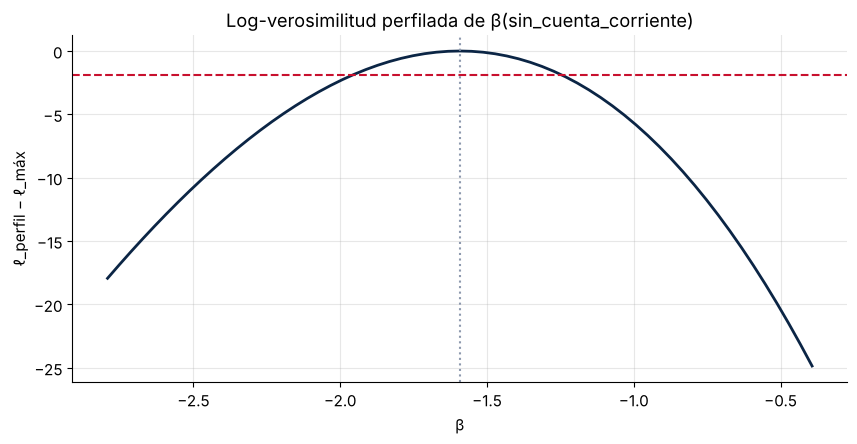

In [7]:
j = "sin_cuenta_corriente"
grid = np.linspace(m1.params[j] - 1.2, m1.params[j] + 1.2, 61)
perfil = []
for b in grid:
    off = b * X1[j]
    mm = sm.GLM(g["default"], X1.drop(columns=j), family=sm.families.Binomial(), offset=off).fit()
    perfil.append(mm.llf)
perfil = np.array(perfil)
dentro = grid[perfil >= m1.llf - stats.chi2.ppf(0.95, 1) / 2]
wald_ci = m1.conf_int().loc[j].values
print(f"IC Wald:      [{wald_ci[0]:.3f}, {wald_ci[1]:.3f}]")
print(f"IC perfilado: [{dentro.min():.3f}, {dentro.max():.3f}]  (resolución de la grilla: {grid[1] - grid[0]:.3f})")
plt.plot(grid, perfil - m1.llf, color=AZUL, lw=2); plt.axhline(-1.92, color=ROJO, ls="--"); plt.axvline(m1.params[j], color=GRIS, ls=":")
plt.title(f"Log-verosimilitud perfilada de β({j})"); plt.xlabel("β"); plt.ylabel("ℓ_perfil − ℓ_máx"); plt.show()

## 4. AIC, BIC y deviance
- **Deviance:** $D = -2\ell$ (relativa al modelo saturado). Las diferencias de deviance entre modelos anidados son el estadístico LR.
- **AIC** $= -2\ell + 2k$ y **BIC** $= -2\ell + k\log n$: penalizan la complejidad y permiten comparar modelos **no anidados**. El BIC penaliza más y tiende a elegir modelos más simples.

In [8]:
candidatos = {
    "M0: duración + edad": ["duration_in_month", "age_in_years"],
    "M1: + cuenta y ahorro": ["duration_in_month", "age_in_years", "sin_cuenta_corriente", "ahorro_bajo"],
    "M2: + historia + cuota": ["duration_in_month", "age_in_years", "sin_cuenta_corriente", "ahorro_bajo", "historia_critica", "installment_rate_in_percentage_of_disposable_income"],
    "M3: M2 + log(monto)": ["duration_in_month", "age_in_years", "sin_cuenta_corriente", "ahorro_bajo", "historia_critica", "installment_rate_in_percentage_of_disposable_income", "log_monto"],
}
res = []
for nombre, cols in candidatos.items():
    mm = sm.Logit(g["default"], sm.add_constant(g[cols])).fit(disp=0)
    res.append({"modelo": nombre, "k": len(cols) + 1, "logLik": mm.llf, "deviance": -2 * mm.llf, "AIC": mm.aic, "BIC": mm.bic, "pseudo_R2": mm.prsquared})
r = pd.DataFrame(res).set_index("modelo")
r.style.format({"logLik": "{:.1f}", "deviance": "{:.1f}", "AIC": "{:.1f}", "BIC": "{:.1f}", "pseudo_R2": "{:.3f}"}).highlight_min(subset=["AIC", "BIC"], color="#D8F0E3")

,k,logLik,deviance,AIC,BIC,pseudo_R2
modelo,,,,,,
M0: duración + edad,3,-584.6,1169.2,1175.2,1189.9,0.043
M1: + cuenta y ahorro,5,-523.9,1047.9,1057.9,1082.4,0.142
M2: + historia + cuota,7,-512.1,1024.2,1038.2,1072.6,0.162
M3: M2 + log(monto),8,-511.8,1023.6,1039.6,1078.9,0.162


**Lectura:** M3 agrega `log_monto`, que no es significativo. El AIC casi no cambia y el BIC empeora: la variable no paga su complejidad. En el Módulo 3 veremos la selección de variables de forma sistemática (stepwise, L1, estabilidad).

## 5. Ejercicios
1. Agrega `age_in_years²` al modelo M2. Haz el test LR a mano. ¿Se justifica la curvatura?
2. Calcula el IC perfilado de `historia_critica` y compáralo con el de Wald.
3. ¿Qué modelo elegirías con AIC y cuál con BIC? ¿Por qué pueden diferir?
4. **Reto:** demuestra que para la logística el Hessiano es $-X^\top W X$ con $W = \text{diag}(p_i(1-p_i))$.